# School holidays and bakery turnover

**Author:** Niklas · **Canvas:** block 2 (school-holiday effect)

## Question and hypothesis

Do sales differ on official Schleswig-Holstein school-holiday dates, and does the pattern differ between weekdays and weekends? We test each product group separately. The directional hypothesis is that average turnover is lower during school holidays than outside them, within each weekday/weekend segment.

## Decisions and method

- Training period only: 2013-07-01 through 2017-07-31; validation stays untouched.
- Holiday dates are only the official inclusive start/end dates in `data/school_holidays_sh.csv`. We do not extend them to nearby weekends or public holidays. A weekend is a holiday only if it falls inside an official interval.
- Weekday = Monday–Friday; weekend = Saturday–Sunday. Products 1–6 are tested separately. Seasonal bread (group 6) is present only in its selling season.
- We use a one-sided Welch two-sample t-test (`holiday < non-holiday`), which allows unequal variances. We report a 95% two-sided confidence interval for the holiday-minus-non-holiday mean difference. Holm-adjusted p-values account for 12 comparisons (6 groups × 2 day types).
- 2014-05-05 is excluded under decision D2. Missing product rows are not converted to zero (D3), so comparisons use dates with an observed row for that product.

These are observational comparisons, not proof of causation. Separate tests can show evidence within a day type; significance in one segment but not the other does not itself prove the effects differ between weekdays and weekends.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE_URL = 'https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/'
TRAIN_START, TRAIN_END = '2013-07-01', '2017-07-31'
EXCLUDED_DAYS = ['2014-05-05']  # D2: unusual turnover after a multi-day closure
GROUPS = {1: 'Bread', 2: 'Rolls', 3: 'Croissants', 4: 'Confectionery', 5: 'Cakes', 6: 'Seasonal bread'}
DAY_TYPES = ['Weekday', 'Weekend']

# Locate the repo root so this works from either the repo or this notebook's folder.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'school_holidays_sh.csv').exists())
school_periods = pd.read_csv(PROJECT_ROOT / 'data' / 'school_holidays_sh.csv', parse_dates=['start', 'end'])
# Match the team's convention: course sales data are read from the documented source.
sales = pd.read_csv(BASE_URL + 'umsatzdaten_gekuerzt.csv', parse_dates=['Datum'])
print(f'{len(sales):,} sales rows; {len(school_periods)} official holiday periods')

9,334 sales rows; 36 official holiday periods


## 1. Prepare and check the comparison data

Each row stays one product group on one open day. We mark official school-holiday dates from the CSV and classify weekends independently. No extra dates are added around a school break. The checks below help catch date-range or calendar mistakes before testing.

In [2]:
# Expand inclusive official periods into dates; do not extend to adjacent days.
holiday_dates = set()
for row in school_periods.itertuples(index=False):
    holiday_dates.update(pd.date_range(row.start, row.end, freq='D'))

analysis = sales.loc[sales.Datum.between(TRAIN_START, TRAIN_END) & ~sales.Datum.isin(pd.to_datetime(EXCLUDED_DAYS))].copy()
analysis['school_holiday'] = analysis.Datum.isin(holiday_dates)
analysis['day_type'] = np.where(analysis.Datum.dt.dayofweek >= 5, 'Weekend', 'Weekday')
analysis['group_name'] = analysis.Warengruppe.map(GROUPS)
analysis['holiday_label'] = analysis.school_holiday.map({True: 'School holiday', False: 'Outside school holidays'})

assert school_periods[['start', 'end']].notna().all().all()
assert (school_periods.start <= school_periods.end).all()
assert analysis.Datum.between(TRAIN_START, TRAIN_END).all()
assert not analysis.Datum.isin(pd.to_datetime(EXCLUDED_DAYS)).any()
assert analysis[['Umsatz', 'school_holiday', 'day_type', 'group_name']].notna().all().all()
assert set(analysis.Warengruppe.unique()) == set(GROUPS)

print(f'Training rows: {len(analysis):,}; dates: {analysis.Datum.min().date()} to {analysis.Datum.max().date()}')
print(f'Official holiday dates represented: {analysis.loc[analysis.school_holiday].Datum.nunique()}')

Training rows: 7,488; dates: 2013-07-01 to 2017-07-31
Official holiday dates represented: 330


## 2. Check sample sizes

We show the number of observed sales rows in each holiday/non-holiday and weekday/weekend cell before testing. Confectionery has missing product-day rows; seasonal bread appears only in season. Missing rows are not interpreted as zero sales. Small cells make a t-test less reliable, so keep these counts beside the results.

In [3]:
cell_counts = (analysis.groupby(['group_name', 'day_type', 'holiday_label'], observed=True)
    .agg(n=('Umsatz', 'size'), mean_turnover=('Umsatz', 'mean'), median_turnover=('Umsatz', 'median')).reset_index())
cell_counts.sort_values(['group_name', 'day_type', 'holiday_label']).round(1)

,group_name,day_type,holiday_label,n,mean_turnover,median_turnover
0,Bread,Weekday,Outside school holidays,798,120.4,119.1
1,Bread,Weekday,School holiday,246,143.5,140.9
2,Bread,Weekend,Outside school holidays,333,103.1,96.7
3,Bread,Weekend,School holiday,84,135.2,132.2
4,Cakes,Weekday,Outside school holidays,798,253.5,249.8
5,Cakes,Weekday,School holiday,246,311.2,291.0
6,Cakes,Weekend,Outside school holidays,333,306.3,298.0
7,Cakes,Weekend,School holiday,84,346.7,322.0
8,Confectionery,Weekday,Outside school holidays,777,78.2,74.1
9,Confectionery,Weekday,School holiday,224,78.6,75.4


## 3. Welch t-tests and confidence intervals

For each product and day type, the difference is `holiday mean − non-holiday mean`; negative values match our hypothesis. Welch's test does not assume equal variances. The 95% interval uses Welch–Satterthwaite degrees of freedom. Holm-adjusted p-values account for all 12 tests. Confidence intervals are per comparison, not simultaneous intervals.

In [4]:
def welch_holiday_test(frame):
    # Test the pre-stated directional hypothesis: holiday mean is lower.
    h = frame.loc[frame.school_holiday, 'Umsatz'].to_numpy(dtype=float)
    o = frame.loc[~frame.school_holiday, 'Umsatz'].to_numpy(dtype=float)
    nh, no = len(h), len(o)
    if min(nh, no) < 2:
        return dict(n_holiday=nh, n_nonholiday=no, holiday_mean=np.nan, nonholiday_mean=np.nan, difference=np.nan, ci_low=np.nan, ci_high=np.nan, t_stat=np.nan, df=np.nan, p_one_sided=np.nan)
    mh, mo = h.mean(), o.mean()
    vh, vo = h.var(ddof=1), o.var(ddof=1)
    diff = mh - mo
    se2 = vh / nh + vo / no
    se = np.sqrt(se2)
    # Welch-Satterthwaite degrees of freedom for the unequal-variance standard error.
    df = se2**2 / ((vh / nh)**2 / (nh - 1) + (vo / no)**2 / (no - 1))
    margin = stats.t.ppf(0.975, df) * se  # two-sided 95% confidence interval
    test = stats.ttest_ind(h, o, equal_var=False, alternative='less')
    return dict(n_holiday=nh, n_nonholiday=no, holiday_mean=mh, nonholiday_mean=mo, difference=diff, ci_low=diff-margin, ci_high=diff+margin, t_stat=diff/se, df=df, p_one_sided=test.pvalue)

rows = []
for group_id, product in GROUPS.items():
    for day_type in DAY_TYPES:
        subset = analysis.loc[(analysis.Warengruppe == group_id) & (analysis.day_type == day_type)]
        rows.append({'group_id': group_id, 'product': product, 'day_type': day_type, **welch_holiday_test(subset)})
results = pd.DataFrame(rows)
valid = results.p_one_sided.notna()
results['p_holm'] = np.nan
# Holm adjustment: sort p-values, multiply by remaining test count, then enforce monotonicity.
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted_sorted = np.maximum.accumulate((len(p_values) - np.arange(len(p_values))) * p_values[order])
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    return adjusted

results.loc[valid, 'p_holm'] = holm_adjust(results.loc[valid, 'p_one_sided'])
results['difference_pct'] = 100 * results.difference / results.nonholiday_mean
columns = ['product', 'day_type', 'n_holiday', 'n_nonholiday', 'holiday_mean', 'nonholiday_mean', 'difference', 'ci_low', 'ci_high', 'difference_pct', 'p_one_sided', 'p_holm']
results[columns].round(3)

,product,day_type,n_holiday,n_nonholiday,holiday_mean,nonholiday_mean,difference,ci_low,ci_high,difference_pct,p_one_sided,p_holm
0,Bread,Weekday,246,798,143.468,120.377,23.090,17.623,28.558,19.182,1.000,1.000
1,Bread,Weekend,84,333,135.208,103.111,32.098,16.835,47.360,31.129,1.000,1.000
2,Rolls,Weekday,246,798,485.472,330.172,155.299,138.008,172.591,47.036,1.000,1.000
3,Rolls,Weekend,84,333,614.038,494.302,119.735,86.014,153.457,24.223,1.000,1.000
4,Croissants,Weekday,246,798,212.128,127.567,84.560,73.720,95.401,66.287,1.000,1.000
5,Croissants,Weekend,84,333,265.345,189.609,75.736,55.849,95.622,39.943,1.000,1.000
6,Confectionery,Weekday,224,777,78.578,78.245,0.333,-2.825,3.490,0.425,0.582,1.000
7,Confectionery,Weekend,79,328,104.699,114.298,-9.599,-19.464,0.265,-8.399,0.028,0.310
8,Cakes,Weekday,246,798,311.152,253.460,57.693,35.444,79.941,22.762,1.000,1.000
9,Cakes,Weekend,84,333,346.683,306.265,40.418,3.886,76.950,13.197,0.985,1.000


## 4. Plot the mean differences

Points are holiday-minus-non-holiday mean turnover; bars show 95% confidence intervals. The zero line means no difference. Interpret significance using the Holm-adjusted p-values in the table.

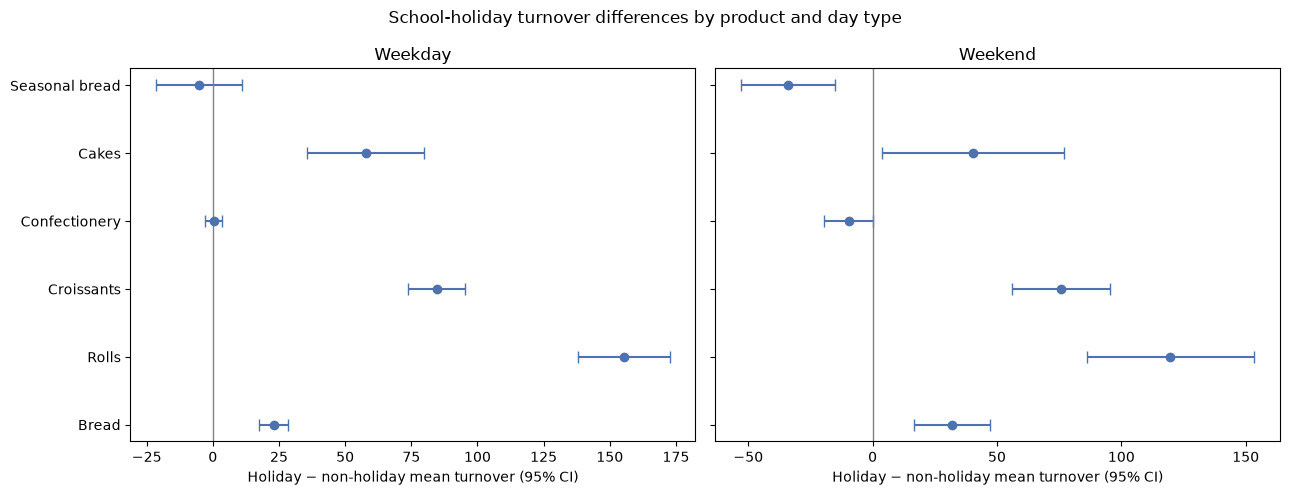

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, day_type in zip(axes, DAY_TYPES):
    part = results.loc[results.day_type == day_type].sort_values('group_id')
    y = np.arange(len(part))
    ax.errorbar(part.difference, y, xerr=[part.difference-part.ci_low, part.ci_high-part.difference], fmt='o', color='#4c72b0', capsize=4)
    ax.axvline(0, color='grey', lw=1)
    ax.set_yticks(y, part['product'])
    ax.set_title(day_type)
    ax.set_xlabel('Holiday − non-holiday mean turnover (95% CI)')
fig.suptitle('School-holiday turnover differences by product and day type')
fig.tight_layout()
plt.show()

## Interpretation and limitations

A negative difference means the observed average was lower on official school-holiday dates. The one-sided p-value tests the predicted direction; use its Holm-adjusted value across the 12 comparisons. The confidence interval describes uncertainty in each difference and is not multiplicity-adjusted. Compare weekday and weekend panels descriptively: separate t-tests do not directly test whether the two holiday effects differ.

This simple t-test does not control for month, year, or weather, even though school holidays happen at particular times of year. Nearby days can also be related, while the t-test treats rows as independent. Results are associations, not causal effects. Missing product rows are excluded rather than treated as zero, and seasonal bread is analysed only on its observed in-season dates.
## What this run found

For the five regular product groups (bread, rolls, croissants, confectionery, and cakes), the one-sided lower-turnover hypothesis is not supported after Holm adjustment: every adjusted p-value is at least 0.310. Most estimated differences are positive. The clearest negative point estimate among these products is confectionery on weekends (−9.6 turnover, or −8.4%; 95% CI −19.5 to 0.3; Holm-adjusted p = 0.310), which remains inconclusive.

Seasonal bread on weekends is the only comparison with an adjusted p-value below 0.05: the holiday mean is 34.1 lower (−47.8%; 95% CI −53.0 to −15.1; Holm-adjusted p = 0.013). This estimate is based on only **7 school-holiday weekend rows**, so it is fragile and should be treated as a lead for discussion, not a firm finding. The t-tests do not adjust for month, year, or weather, which may explain some of the positive differences or the seasonal-bread pattern.